In [1]:
import numpy as np
import matplotlib.pyplot as plt
import numpy as np
import os
import yaml

import numcosmo_II as nc

from datetime import datetime
from pathlib import Path

## Initial Configurations

In [2]:
current_dir  = Path.cwd()
project_root = current_dir.parent if current_dir.name == 'analysis' else current_dir
yaml_path = project_root / 'config' / "setup.yaml"

print( 100 * "=" )
print( "Loading Initial Setup" )
print( f"Project root set as: {project_root}" )
print( 100 * "=" + "\n" )

with open(yaml_path, "r", encoding = "utf-8" ) as config_file:
    config = yaml.safe_load( config_file )

print(f"{yaml.dump( config, sort_keys = False, allow_unicode = True ) }")

config_out   = config[ "output" ]
output_dir   = project_root / config_out["root"]
os.makedirs(output_dir, exist_ok=True)

timestamp     = datetime.now().strftime( "%Y%m%d_%H%M%S" )
base_filename = f"{config_out[ 'base_name' ]}_{timestamp}"
output_base   = output_dir / base_filename

Loading Initial Setup
Project root set as: /home/alex/Área de trabalho/Pós-Graduação/Disciplinas/Numerical_Cosmology_1/EP_II

cosmology:
  h: 0.6737
  Omega_r: 0.0
  Omega_m: 0.315
  Omega_lambda: 0.685
  w0_fld: -1.0
  wa_fld: 0.0
growth:
  a_i: 0.0001
  a_f: 1.0
  num_points: 400
  solver:
    rtol: 1.0e-08
    atol: 1.0e-10
spt:
  box_size_L: 500.0
  grid_Ng: 64
  scale_factor_aref: 1.0
  pk_num_bins: 20
  bispectrum_num_bins: 15
  skewness:
    R_min: 2.0
    R_max: 30.0
    num_radii: 15
ensemble:
  num_realizations: 25
  seed_start: 12345
output:
  root: analysis/output
  base_name: Test



In [3]:
#_____ cosmomological models ______#

cosmo_params = config[ "cosmology" ]
lcdm_model = nc.FLRW( **cosmo_params )

eds_params = cosmo_params.copy()
eds_params.update( {"Omega_m": 1.0, "Omega_lambda": 0.0, "Omega_r": 0.0} )
eds_model = nc.FLRW( **eds_params )

ocdm_params = cosmo_params.copy()
ocdm_params.update( {"Omega_m": cosmo_params[ "Omega_m" ], "Omega_lambda": 0.0, "Omega_r": 0.0} )
ocdm_model  = nc.FLRW( **ocdm_params )

#_________________________________#

a_i = config[ "growth" ][ "a_i" ]
a_f = config[ "growth" ][ "a_f" ]

N_span = [ np.log( a_i ), np.log( a_f ) ]
N_eval = np.linspace( N_span[ 0 ], N_span[ 1 ], config[ "growth" ][ "num_points" ] )
a_eval = np.exp( N_eval )

solver_opts = config[ "growth" ][ "solver" ]

spt_cfg = config[ "spt" ]
gf      = nc.GaussianField(
    L    = spt_cfg[ "box_size_L" ], 
    Ng   = spt_cfg[ "grid_Ng" ], 
    aref = spt_cfg[ "scale_factor_aref" ]
)
spt = nc.SPTStatistics(gf)

ensem_cfg = config['ensemble']

## Cosmological Analysis and Tests (Ex 1)

### $D(a)$ and $f(a)$ Validation

In [4]:
sol_eds  = eds_model.solve_growth(  N = N_span, y0 = [ a_i, a_i ], **solver_opts)
sol_lcdm = lcdm_model.solve_growth( N = N_span, y0 = [ a_i, a_i ], **solver_opts)
sol_ocdm = ocdm_model.solve_growth( N = N_span, y0 = [ a_i, a_i ], **solver_opts)

In [5]:
D_eds,  f_eds  = eds_model.get_growth_observables(  sol_eds,  N_eval = N_eval )
D_lcdm, f_lcdm = lcdm_model.get_growth_observables( sol_lcdm, N_eval = N_eval )
D_ocdm, f_ocdm = ocdm_model.get_growth_observables( sol_ocdm, N_eval = N_eval )

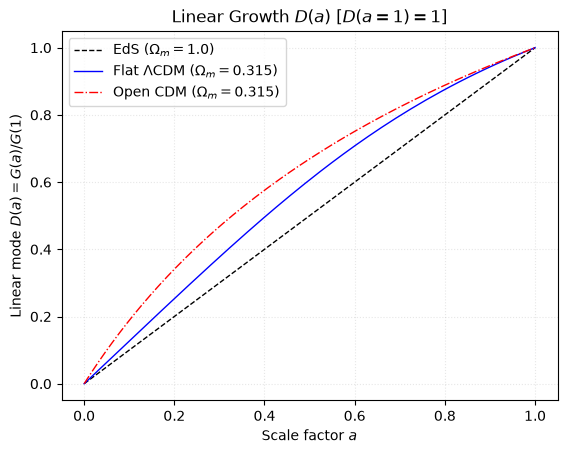

Linear Growth plot saved to: /home/alex/Área de trabalho/Pós-Graduação/Disciplinas/Numerical_Cosmology_1/EP_II/analysis/output/Test_20261010_155353_linear_growth.png



In [6]:
plt.Figure( figsize = ( 10, 6 ) )

plt.plot( a_eval, D_eds,  'k--', lw = 1, label = r'EdS ($\Omega_m=1.0$)' )
plt.plot( a_eval, D_lcdm, 'b-',  lw = 1, label = rf'Flat $\Lambda$CDM ($\Omega_m={lcdm_model.O_matter:.3f}$)' )
plt.plot( a_eval, D_ocdm, 'r-.', lw = 1, label = rf'Open CDM ($\Omega_m={ocdm_model.O_matter:.3f}$)' )

plt.xlabel( r'Scale factor $a$' )
plt.ylabel( r'Linear mode $D(a) = G(a)/G(1)$' )

plt.title( r'Linear Growth $D(a)$ [$D(a=1)=1$]' )

plt.grid( True, ls = ':', alpha = 0.3 )
plt.legend()


linear_growth_path = f"{output_base}_linear_growth.png"
plt.savefig( linear_growth_path, dpi = 300, bbox_inches = "tight" )
#plt.close()
plt.show()
print( f"Linear Growth plot saved to: {linear_growth_path}\n" )

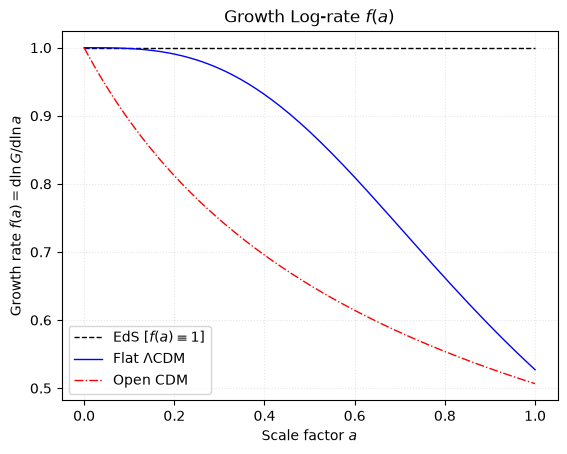

Linear Growth plot saved to: /home/alex/Área de trabalho/Pós-Graduação/Disciplinas/Numerical_Cosmology_1/EP_II/analysis/output/Test_20261010_155353_growth_rate.png



In [7]:
plt.Figure( figsize = ( 10, 6 ) )

plt.plot( a_eval, f_eds,  'k--', lw = 1, label = r'EdS [$f(a) \equiv 1$]' )
plt.plot( a_eval, f_lcdm, 'b-',  lw = 1, label = r'Flat $\Lambda$CDM' )
plt.plot( a_eval, f_ocdm, 'r-.', lw = 1, label = r'Open CDM' )

plt.xlabel( r'Scale factor $a$' )
plt.ylabel( r'Growth rate $f(a) = \mathrm{d}\ln G / \mathrm{d}\ln a$' )

plt.title( r'Growth Log-rate $f(a)$' )

plt.grid( True, ls=':', alpha = 0.3 )
plt.legend()

growth_rate_path = f"{output_base}_growth_rate.png"
plt.savefig( growth_rate_path, dpi = 300, bbox_inches = "tight" )
#plt.close()
plt.show()
print( f"Linear Growth plot saved to: {growth_rate_path}\n" )

In [8]:
print( f"EdS (a=1):  D = {D_eds[-1]:.6f} (expected 1.0) | f = {f_eds[-1]:.6f} (expected 1.0)" )
print( f"LCDM (a=1): D = {D_lcdm[-1]:.6f} | f = {f_lcdm[-1]:.6f}" )
print( f"OCDM (a=1): D = {D_ocdm[-1]:.6f} | f = {f_ocdm[-1]:.6f}" )

EdS (a=1):  D = 1.000000 (expected 1.0) | f = 1.000000 (expected 1.0)
LCDM (a=1): D = 1.000000 | f = 0.527103
OCDM (a=1): D = 1.000000 | f = 0.506548


### Quadrature vs ODE

In [9]:
a_test      = np.linspace( 0.05, 1.0, 25 )
G_ode_vals  = [ sol_lcdm.sol( np.log( a_v ) )[ 0 ] for a_v in a_test ]
G_quad_vals = [ lcdm_model.growth_quadrature( a_v ) for a_v in a_test ]

err_rel = np.abs( np.array( G_ode_vals ) - np.array( G_quad_vals ) ) / np.array( G_quad_vals )
print(f"Maximum relative error: {np.max(err_rel):.3e}")

Maximum relative error: 2.124e-07


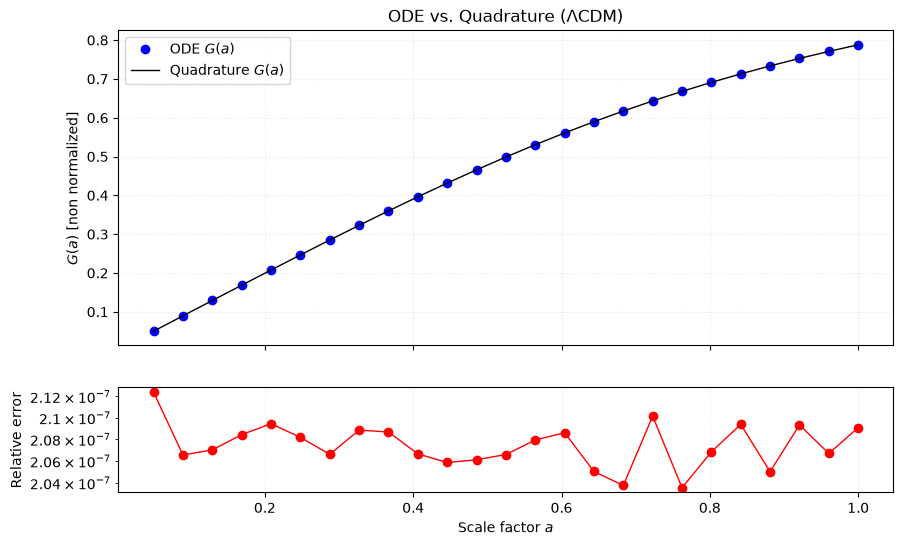

Linear Growth plot saved to: /home/alex/Área de trabalho/Pós-Graduação/Disciplinas/Numerical_Cosmology_1/EP_II/analysis/output/Test_20261010_155353_quadrature_ODE_validation.png



In [10]:
fig, ( ax1, ax2 ) = plt.subplots( 2, 1, figsize = ( 10, 6 ), sharex = True, gridspec_kw = {'height_ratios': [ 3, 1 ]} )

ax1.plot( a_test, G_ode_vals,  'bo', label = r'ODE $G(a)$' )
ax1.plot( a_test, G_quad_vals, 'k-', lw = 1, label = r'Quadrature $G(a)$' )

ax1.set_ylabel( r'$G(a)$ [non normalized]' )
ax1.set_title( r'ODE vs. Quadrature ($\Lambda\mathrm{CDM}$)' )

ax1.legend()
ax1.grid( True, ls=':', alpha = 0.3)

ax2.plot( a_test, err_rel, 'r-o', lw = 1 )
ax2.set_yscale( 'log' )
ax2.set_xlabel( r'Scale factor $a$' )
ax2.set_ylabel( r'Relative error' )
ax2.grid( True, ls=':', alpha = 0.3 )

quadrature_ODE_validation_path = f"{output_base}_quadrature_ODE_validation.png"
plt.savefig( quadrature_ODE_validation_path, dpi = 300, bbox_inches = "tight" )
#plt.close()
plt.show()
print( f"Linear Growth plot saved to: {quadrature_ODE_validation_path}\n" )

### Initial Conditions Sensibility

In [11]:
a_i_list = [ 1e-3, 1e-4, 1e-5 ]
tol_list = [ ( 1e-6, 1e-8 ), ( 1e-8, 1e-10 ), ( 1e-10, 1e-12 ) ]

print( "=" * 100 )
print( f"{'a_i':<10} | {'rtol, atol':<20} | {'f(a=1)':<14} | {'D(a=1)':<14} | {'Erro Rel. f in a=1':<20}" )
print( "=" * 100 )

f_ref = None

for a_init in a_i_list:
    for rtol, atol in tol_list:
        sol_t = lcdm_model.solve_growth(
            N = [ np.log( a_init ), 0.0 ], y0 = [ a_init, a_init ], rtol = rtol, atol = atol
        )
        D_t, f_t = lcdm_model.get_growth_observables( sol_t, N_eval = [ 0.0 ] )
        
        if f_ref is None:
            f_ref = f_t[ 0 ]
            diff  = 0.0
        else:
            diff = abs( f_t[0] - f_ref ) / f_ref

        print( f"{a_init:<10.1e} | {str((rtol, atol)):<20} | {f_t[0]:<14.8f} | {D_t[0]:<14.8f} | {diff:<20.2e}" )
print("=" * 100)

a_i        | rtol, atol           | f(a=1)         | D(a=1)         | Erro Rel. f in a=1  
1.0e-03    | (1e-06, 1e-08)       | 0.52710275     | 1.00000000     | 0.00e+00            
1.0e-03    | (1e-08, 1e-10)       | 0.52710320     | 1.00000000     | 8.54e-07            
1.0e-03    | (1e-10, 1e-12)       | 0.52710320     | 1.00000000     | 8.62e-07            
1.0e-04    | (1e-06, 1e-08)       | 0.52710281     | 1.00000000     | 1.24e-07            
1.0e-04    | (1e-08, 1e-10)       | 0.52710320     | 1.00000000     | 8.54e-07            
1.0e-04    | (1e-10, 1e-12)       | 0.52710320     | 1.00000000     | 8.62e-07            
1.0e-05    | (1e-06, 1e-08)       | 0.52710276     | 1.00000000     | 2.71e-08            
1.0e-05    | (1e-08, 1e-10)       | 0.52710320     | 1.00000000     | 8.54e-07            
1.0e-05    | (1e-10, 1e-12)       | 0.52710320     | 1.00000000     | 8.62e-07            


## SPT and Mode Coupling (Ex 2)

In [12]:
gf.P_linear = lambda k, a = 1.0: np.where( k == 0, 0.0, 10.0 * ( k / 0.1 ) * np.exp( -( k / 0.8 ) ** 2 ) )

delta_1_x, delta_1_k = gf.Gaussian_field()

delta_2_x, delta_2_k = spt.compute_delta_2( delta_1_k )

delta_tot_k = delta_1_k + delta_2_k
delta_tot_x = delta_1_x + delta_2_x

k_p, P_1, n_modes = spt.spt_power_spectrum( delta_1_k,   num_bins = spt_cfg[ 'pk_num_bins' ] )
_, P_tot, _       = spt.spt_power_spectrum( delta_tot_k, num_bins = spt_cfg[ 'pk_num_bins' ] )

print(f"Linear variance: sigma_1^2 = {np.var(delta_1_x):.4e}")
print(f"Total variance:  sigma_tot^2 = {np.var(delta_tot_x):.4e}")

Linear variance: sigma_1^2 = 6.0978e-02
Total variance:  sigma_tot^2 = 6.8827e-02


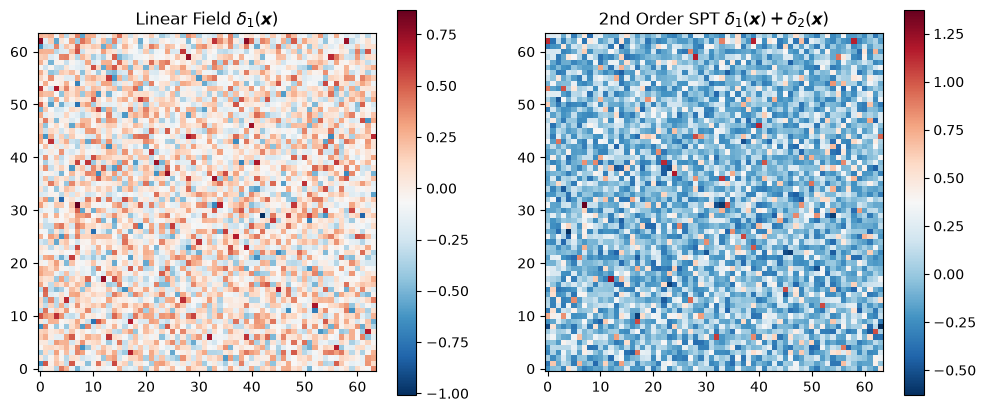

Linear Vs 2nd Order SPT plot saved to: /home/alex/Área de trabalho/Pós-Graduação/Disciplinas/Numerical_Cosmology_1/EP_II/analysis/output/Test_20261010_155353_Linear_Vs_2ndO_SPT.png



In [13]:
fig = plt.figure( figsize = ( 12, 5 ) )

ax1 = fig.add_subplot( 1, 2, 1 )
im1 = ax1.imshow(delta_1_x[ :, :, 0 ], cmap = 'RdBu_r', origin = 'lower')

ax1.set_title( r'Linear Field $\delta_1(\boldsymbol{x})$' )
plt.colorbar( im1, ax = ax1)

ax2 = fig.add_subplot( 1, 2, 2 )
im2 = ax2.imshow( delta_tot_x[ :, :, 0 ], cmap ='RdBu_r', origin = 'lower' )
ax2.set_title( r'2nd Order SPT $\delta_1(\boldsymbol{x}) + \delta_2(\boldsymbol{x})$' )
plt.colorbar( im2, ax = ax2 )

Linear_Vs_2ndO_SPT_path = f"{output_base}_Linear_Vs_2ndO_SPT.png"
plt.savefig( Linear_Vs_2ndO_SPT_path, dpi = 300, bbox_inches = "tight" )
#plt.close()
plt.show()
print( f"Linear Vs 2nd Order SPT plot saved to: {Linear_Vs_2ndO_SPT_path}\n" )


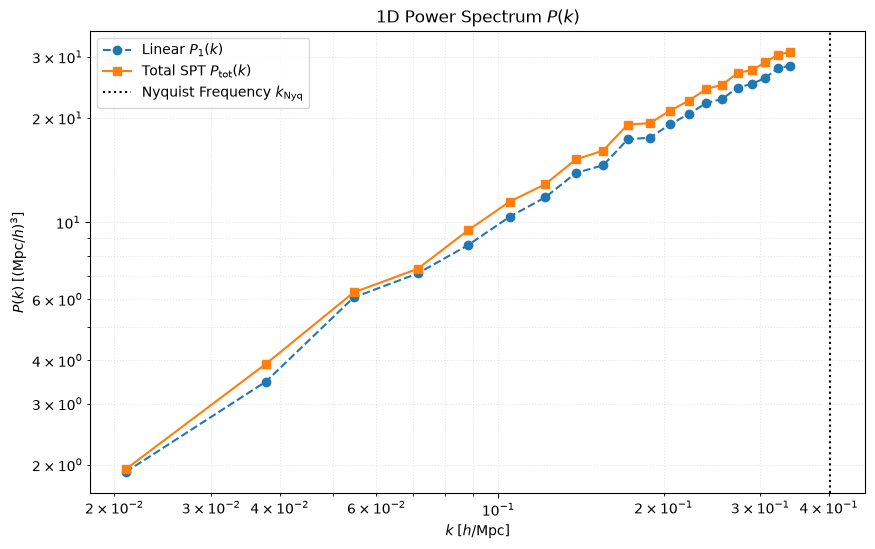

1D Power Spectrum plot saved to: /home/alex/Área de trabalho/Pós-Graduação/Disciplinas/Numerical_Cosmology_1/EP_II/analysis/output/Test_20261010_155353_Pk_1D_comparison.png



In [14]:
plt.figure( figsize = ( 10, 6 ) )

plt.plot(k_p, P_1,   'o--', label = r'Linear $P_1(k)$' )
plt.plot(k_p, P_tot, 's-',  label = r'Total SPT $P_{\mathrm{tot}}(k)$' )

plt.axvline( np.pi * gf.Ng / gf.L, color='k', ls=':', label = r'Nyquist Frequency $k_{\mathrm{Nyq}}$')
plt.xscale( 'log' )
plt.yscale( 'log' )

plt.xlabel( r'$k \; [h/\mathrm{Mpc}]$' )
plt.ylabel(r'$P(k) \; [(\mathrm{Mpc}/h)^3]$' )

plt.title( r'1D Power Spectrum $P(k)$' )

plt.grid( True, which = "both", ls = ":", alpha = 0.3 )
plt.legend()

Pk_1D_path = f"{output_base}_Pk_1D_comparison.png"
plt.savefig( Pk_1D_path, dpi = 300, bbox_inches = "tight" )
#plt.close()
plt.show()
print( f"1D Power Spectrum plot saved to: {Pk_1D_path}\n" )

In [15]:
gf.P_linear = lambda k, a = 1.0: np.where( k == 0, 0.0, 0.1 * ( k / 0.1 ) * np.exp( - (k / 0.8 ) ** 2 ) )

delta_1_x, delta_1_k = gf.Gaussian_field()
delta_2_x, delta_2_k = spt.compute_delta_2( delta_1_k )

delta_tot_k = delta_1_k + delta_2_k
delta_tot_x = delta_1_x + delta_2_x

print( f"Linear variance sigma_1^2 = {np.var( delta_1_x ):.4e}" )

k_b, B_meas, B_tree = spt.spt_equilateral_bispectrum(
    delta_tot_k, num_bins = spt_cfg[ 'bispectrum_num_bins' ]
)

R_array = np.linspace( 4.0, 12.0, 8 )
_, S3_vals = spt.spt_S3_profile( delta_tot_x, R_array )

Linear variance sigma_1^2 = 6.0978e-04


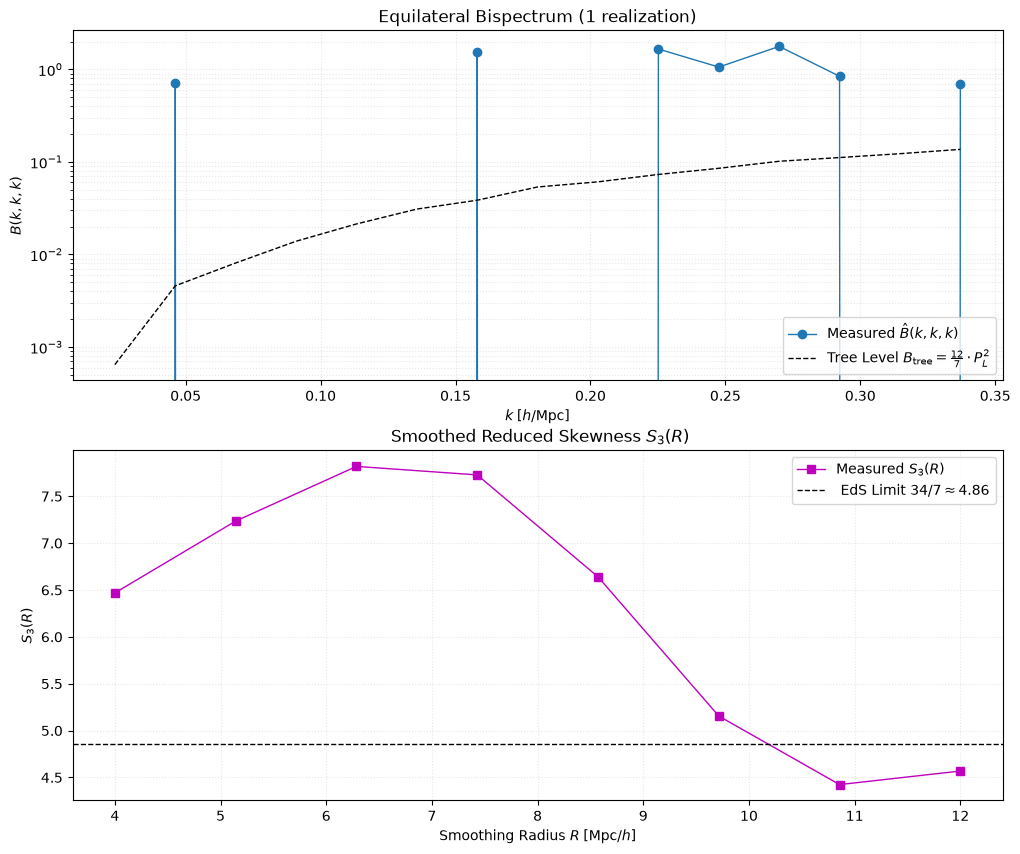

Bispectrum and S_3(R) single realization plot saved to: /home/alex/Área de trabalho/Pós-Graduação/Disciplinas/Numerical_Cosmology_1/EP_II/analysis/output/Test_20261010_155353_Bispectrum_S3R_1rea.png



In [16]:
fig, axes = plt.subplots(2, 1, figsize=(12, 10))

axes[0].plot( k_b, B_meas, 'o-',  lw = 1, label = r'Measured $\hat{B}(k,k,k)$')
axes[0].plot( k_b, B_tree, 'k--', lw = 1, label = r'Tree Level $B_{\mathrm{tree}} = \frac{12}{7}\cdot P_L^2$')

axes[0].set_yscale( 'log' )
axes[0].set_xlabel( r'$k \; [h/\mathrm{Mpc}]$' )
axes[0].set_ylabel( r'$B(k,k,k)$' )

axes[0].set_title( r'Equilateral Bispectrum (1 realization)' )
axes[0].grid( True, which = "both", ls = ":", alpha = 0.3 )
axes[0].legend()


axes[1].plot( R_array, S3_vals, 's-m', lw=1, label = r'Measured $S_3(R)$' )
axes[1].axhline( 34.0/7.0, color = 'k', linestyle='--', lw = 1, label = r' EdS Limit $34/7 \approx 4.86$' )

axes[1].set_xlabel( r'Smoothing Radius $R \; [\mathrm{Mpc}/h]$' )
axes[1].set_ylabel( r'$S_3(R)$' )
axes[1].set_title( r' Smoothed Reduced Skewness $S_3(R)$')
axes[1].grid( True, ls = ":", alpha = 0.3 )
axes[1].legend()

Bispectrum_S3R_1rea_path = f"{output_base}_Bispectrum_S3R_1rea.png"
plt.savefig( Bispectrum_S3R_1rea_path, dpi = 300, bbox_inches = "tight" )
#plt.close()
plt.show()
print( f"Bispectrum and S_3(R) single realization plot saved to: {Bispectrum_S3R_1rea_path}\n" )


In [17]:
ensemble_res = spt.run_ensemble_analysis(
    num_realizations = ensem_cfg[ 'num_realizations' ],
    num_bins         = spt_cfg[ 'bispectrum_num_bins' ],
    R_array          = np.linspace( 4.0, 10.0, 7 )
)

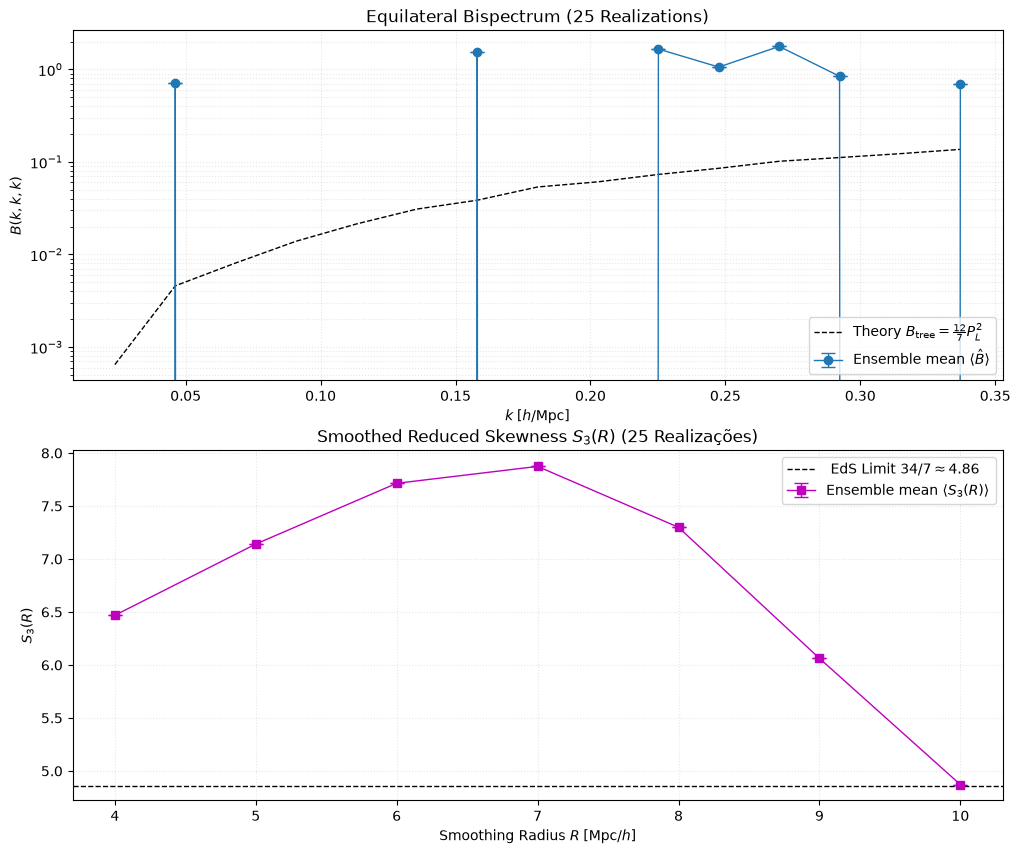

Bispectrum and S_3(R) ensemble realization plot saved to: /home/alex/Área de trabalho/Pós-Graduação/Disciplinas/Numerical_Cosmology_1/EP_II/analysis/output/Test_20261010_155353_Bispectrum_S3R_ensemble.png



In [18]:
fig, axes = plt.subplots(2, 1, figsize=(12, 10))

axes[0].errorbar(
    ensemble_res[ "k_b" ], ensemble_res[ "B_mean" ], yerr = ensemble_res[ "B_std" ],
    fmt = 'o-', capsize = 5, lw = 1, label = r'Ensemble mean $\langle \hat{B} \rangle$'
)

axes[0].plot(
    ensemble_res[ "k_b" ], ensemble_res["B_tree"], 'k--', lw = 1,
    label = r'Theory $B_{\mathrm{tree}} = \frac{12}{7}P_L^2$'
)

axes[0].set_yscale( 'log' )
axes[0].set_xlabel( r'$k \; [h/\mathrm{Mpc}]$' )
axes[0].set_ylabel( r'$B(k,k,k)$' )
axes[0].set_title(rf'Equilateral Bispectrum ({ensem_cfg["num_realizations"]} Realizations)')
axes[0].grid( True, which = "both", ls = ":", alpha = 0.3 )
axes[0].legend()

axes[1].errorbar(
    ensemble_res[ "R_array" ], ensemble_res[ "S3_mean" ], yerr = ensemble_res[ "S3_std" ],
    fmt = 's-m', capsize = 5, lw = 1, label = r'Ensemble mean $\langle S_3(R) \rangle$'
)
axes[1].axhline( 34.0/7.0, color = 'k', linestyle='--', lw = 1, label = r' EdS Limit $34/7 \approx 4.86$' )

axes[1].set_xlabel( r'Smoothing Radius $R \; [\mathrm{Mpc}/h]$' )
axes[1].set_ylabel( r'$S_3(R)$' )

axes[1].set_title( rf'Smoothed Reduced Skewness $S_3(R)$ ({ensem_cfg[ "num_realizations" ]} Realizações)' )
axes[1].grid( True, ls = ":", alpha = 0.3 )
axes[1].legend()

Bispectrum_S3R_ensemble_path = f"{output_base}_Bispectrum_S3R_ensemble.png"
plt.savefig( Bispectrum_S3R_ensemble_path, dpi = 300, bbox_inches = "tight" )
#plt.close()
plt.show()
print( f"Bispectrum and S_3(R) ensemble realization plot saved to: {Bispectrum_S3R_ensemble_path}\n" )
